In [ ]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.core.paths import (
    BEHAVIORAL_RESULTS_FILENAME,
    GEOMETRIC_RESULTS_FILENAME,
    METRICS_DIR,
)
from src.core.utils import(
    AggregateEstimators,
    MetricTypeEnum,
    PoolingTypeEnum,
    SingleEstimatorPrefixes,
)
from src.core.config import AAE_FEATURES


type Style = dict[str, float | int | str]


CONTROL_STYLE = {
    'linestyle': '-',
    'linewidth': 2,
    'color': 'black',
    'alpha': 1.0,
}
CHORDAL_MEAN_STYLE = {
    'linestyle': '--',
    'linewidth': 2,
    'alpha': 0.8,
}
LEACE_STYLE = {
    'linestyle': '--',
    'linewidth': 2,
    'alpha': 0.8,
}
SUPERVISED_STYLE = {
    'linestyle': '-',
    'linewidth': 2,
    'alpha': 0.8,
}
SVD_STYLE = {
    'linestyle': ':',
    'linewidth': 2,
    'alpha': 0.8,
}
STYLE_MAP = {
    AggregateEstimators.CONTROL: CONTROL_STYLE,
    'svd_real_aae_sae_unsupervised': CONTROL_STYLE,

    AggregateEstimators.CHORDAL_MEAN_CORPORA: CHORDAL_MEAN_STYLE,
    AggregateEstimators.CHORDAL_MEAN_ALL: CHORDAL_MEAN_STYLE,

    AggregateEstimators.LEACE_CORPORA: LEACE_STYLE,
    AggregateEstimators.LEACE_ALL: LEACE_STYLE,

    SingleEstimatorPrefixes.SUPERVISED: SUPERVISED_STYLE,
    SingleEstimatorPrefixes.SVD: SVD_STYLE,
}

DEFAULT_FIGSIZE = (5, 3)
DEFAULT_LEGEND_POS = (1.05, 1)
DEFAULT_BAR_WIDTH = 0.4


def _get_estimator_style(
    estimator_name: str,
    style_map: dict[str, Style] = STYLE_MAP
) -> Style:
    for estimator_type, style in style_map.items():
        if estimator_name.startswith(estimator_type):
            return style
    return CONTROL_STYLE


def plot_supervised_chordal_distance_by_layer(
    geometric_results_df: pd.DataFrame,
    target_layers: list[int],
    rank: int,
    pooling_type: PoolingTypeEnum,
    supervised_corpus_name: str,
    style_map: dict[str, Style] = STYLE_MAP,
    figsize: tuple[int, int] = DEFAULT_FIGSIZE,
    legend_pos: tuple[float, float] = DEFAULT_LEGEND_POS,
) -> tuple[plt.Figure, plt.Axes] | None:
    supervised_estimator_name = f'{SingleEstimatorPrefixes.SUPERVISED}{supervised_corpus_name}'
    plot_df = geometric_results_df[
        (geometric_results_df['rank'] == rank) &
        (geometric_results_df['pooling_type'] == pooling_type) &
        ((geometric_results_df['estimator_a_name'] == supervised_estimator_name) |
        (geometric_results_df['estimator_b_name'] == supervised_estimator_name))
    ].copy()

    if plot_df.empty:
        print('Missing Geometric Data')
        return

    plot_df['target_estimator_name'] = plot_df['estimator_a_name'].where(
        plot_df['estimator_b_name'] == supervised_estimator_name,
        plot_df['estimator_b_name'],
    )


    fig, ax = plt.subplots(figsize=figsize)
    estimators = plot_df['target_estimator_name'].unique()
    for estimator_name in estimators:
        estimator_df = plot_df[plot_df['target_estimator_name'] == estimator_name].copy()
        estimator_df.sort_values(by='layer', inplace=True)

        estimator_style = _get_estimator_style(estimator_name, style_map)
        ax.plot(
            estimator_df['layer'],
            estimator_df['chordal_distances'],
            label=estimator_name.replace('_', ' ').title(),
            **estimator_style,
        )

        ax.set_title(
            f'Chordal Distance to Supervised Reference {supervised_corpus_name.replace('_', ' ').title()}\n'
            f'Rank {rank}, {pooling_type.capitalize()} Pooling'
        )
        ax.set_xlabel('Model Layer')
        ax.set_ylabel('Chordal Distance')

        ax.set_xticks(target_layers)
        ax.set_ylim(0, 2.25)
        ax.legend(bbox_to_anchor=legend_pos)
        ax.grid(axis='y', alpha=0.5)
    return fig, ax


def plot_geometric_pooling_type_difference_by_layer(
    geometric_results_df: pd.DataFrame,
    rank: int,
    target_layers: list[int],
    supervised_corpus_name: str,
    style_map: dict[str, Style] = STYLE_MAP,
    figsize: tuple[int, int] = DEFAULT_FIGSIZE,
    legend_pos: tuple[float, float] = DEFAULT_LEGEND_POS,
) -> tuple[plt.Figure, plt.Axes] | None:
    supervised_estimator_name = f'{SingleEstimatorPrefixes.SUPERVISED}{supervised_corpus_name}'
    plot_df = geometric_results_df[
        (geometric_results_df['rank'] == rank) &
        ((geometric_results_df['estimator_a_name'] == supervised_estimator_name) |
        (geometric_results_df['estimator_b_name'] == supervised_estimator_name))
    ].copy()

    if plot_df.empty:
        print('Missing Geometric Data')
        return

    plot_df['target_estimator_name'] = plot_df['estimator_a_name'].where(
        plot_df['estimator_b_name'] == supervised_estimator_name,
        plot_df['estimator_b_name'],
    )

    pivot_df = plot_df.pivot_table(
        index=['layer', 'target_estimator_name'],
        columns='pooling_type',
        values='chordal_distances',
    ).reset_index()
    pivot_df['pooling_difference'] = (pivot_df[PoolingTypeEnum.MEAN] - pivot_df[PoolingTypeEnum.LAST])#.abs()

    fig, ax = plt.subplots(figsize=figsize)
    estimators = pivot_df['target_estimator_name'].unique()
    for estimator_name in estimators:
        estimator_df = pivot_df[pivot_df['target_estimator_name'] == estimator_name].copy()
        estimator_df.sort_values(by='layer', inplace=True)

        estimator_style = _get_estimator_style(estimator_name, style_map)
        ax.plot(
            estimator_df['layer'],
            estimator_df['pooling_difference'],
            label=estimator_name.replace('_', ' ').title(),
            **estimator_style,
        )

        ax.set_title(
            f'Differece of Chordal Distance to Supervised Reference {supervised_corpus_name.replace('_', ' ').title()} across Pooling Type\n'
            f'(Mean - Last), Rank {rank}'
        )
        ax.set_xlabel('Model Layer')
        ax.set_ylabel('Difference in Chordal Distance')

        ax.set_xticks(target_layers)
        ax.legend(bbox_to_anchor=legend_pos)
        ax.grid(axis='y', alpha=0.5)
    return fig, ax


def plot_steering_auc_by_estimator(
    auc_df: pd.DataFrame,
    layer: int,
    rank: int,
    pooling_type: PoolingTypeEnum,
    supervised_corpus_name: str,
    include_act_add: bool = False,
    figsize: tuple[int, int] = DEFAULT_FIGSIZE,
    legend_pos: tuple[float, float] = DEFAULT_LEGEND_POS,
    bar_width: float = DEFAULT_BAR_WIDTH,
) -> tuple[plt.Figure, plt.Axes] | None:
    act_add_mask = auc_df['estimator_name'].str.startswith(SingleEstimatorPrefixes.ACT_ADD)
    if include_act_add:
        rank_mask = (auc_df['rank'] == rank) | act_add_mask
    else:
        rank_mask = (auc_df['rank'] == rank) & ~act_add_mask
    
    plot_df = auc_df[
        (auc_df['layer'] == layer) &
        (auc_df['pooling_type'] == pooling_type) &
        (auc_df['corpus_name'] == supervised_corpus_name) &
        (auc_df['metric'] == MetricTypeEnum.LLR_SHIFT) &
        rank_mask
    ].copy()

    if plot_df.empty:
        print('Missing Behvaioral Data')
        return
    
    plot_df.sort_values(by='auc_pos', ascending=True, inplace=True)
    estimators = plot_df['estimator_name'].tolist()
    y_tick_positions = np.arange(len(estimators))
    fig, ax = plt.subplots(figsize=figsize)

    ax.barh(
        y_tick_positions + bar_width / 2,
        plot_df['auc_pos'],
        height=bar_width,
        label=r'Positive $\alpha$',
    )
    ax.barh(
        y_tick_positions - bar_width / 2,
        plot_df['auc_neg'],
        height=bar_width,
        label=r'Negative $\alpha$',
    )

    subtitle_prefix = 'with ActAdd Baselines ' if include_act_add else ''
    ax.set_title(
        f'LLR Shift Area Under Estimator Steering Curve by Estimator\n'
        f'{subtitle_prefix}Layer {layer}, Rank {rank}, {pooling_type.capitalize()} Pooling, on {supervised_corpus_name.replace('_', ' ').title()} Supervised Pairs'
    )
    ax.set_xlabel('LLR AUC')
    ax.set_ylabel('Estimator')

    ax.set_yticks(y_tick_positions)
    ax.set_yticklabels([
        estimator_name.replace('_', ' ').title()
        for estimator_name in estimators
    ])
    ax.legend(bbox_to_anchor=legend_pos)
    ax.grid(axis='x', alpha=0.3)
    
    return fig, ax


def plot_estimator_feature_auc(
    auc_df: pd.DataFrame,
    estimator_name: str,
    layer: int,
    rank: int,
    pooling_type: PoolingTypeEnum,
    supervised_corpus_name: str,
    feature_names: list[str],
    figsize: tuple[int, int] = DEFAULT_FIGSIZE,
    legend_pos: tuple[float, float] = DEFAULT_LEGEND_POS,
    bar_width: float = DEFAULT_BAR_WIDTH,
) -> tuple[plt.Figure, plt.Axes] | None:
    feature_split_names = [f'{supervised_corpus_name}_{feature_name}' for feature_name in feature_names]
    plot_df = auc_df[
        (auc_df['estimator_name'] == estimator_name) &
        (auc_df['layer'] == layer) &
        (auc_df['rank'] == rank) &
        (auc_df['pooling_type'] == pooling_type) &
        (auc_df['metric'] == MetricTypeEnum.LLR_SHIFT) &
        (auc_df['corpus_name'].isin(feature_split_names)) #
    ].copy()

    if plot_df.empty:
        print('Missing Behavioral Data')
        return

    corpus_prefix = f'{supervised_corpus_name}'
    plot_df['feature_name'] = (
        plot_df['corpus_name']
        .str.replace(corpus_prefix, '')
        .str.replace('_', ' ')
        .str.title()
    )
    plot_df.sort_values(by='auc_pos', ascending=True, inplace=True)
    y_tick_positions = np.arange(len(plot_df))
    fig, ax = plt.subplots(figsize=figsize)

    ax.barh(
        y_tick_positions + bar_width / 2,
        plot_df['auc_pos'],
        height=bar_width,
        label=r'Positive $\alpha$',
    )
    ax.barh(
        y_tick_positions - bar_width / 2,
        plot_df['auc_neg'],
        height=bar_width,
        label=r'Negative $\alpha$',
    )

    ax.set_title(
        f'{estimator_name.replace('_', ' ').title()} Steering AUC\n'
        f'Layer {layer}, Vector Rank {rank}, {pooling_type.capitalize()} Pooling'
    )
    ax.set_xlabel('Dialect LLR Shift AUC (Pos. = AAE)')
    ax.set_ylabel('AAE Feature')
    ax.set_xlim(-0.15, 0.15)
    ax.set_yticks(y_tick_positions)
    ax.set_yticklabels(plot_df['feature_name'])
    ax.legend(bbox_to_anchor=legend_pos)
    ax.grid(axis='x', alpha=0.5)

    return fig, ax


def plot_llr_shift_and_perplexity_by_alpha(
    sweep_df: pd.DataFrame,
    estimator_name: str,
    layer: int,
    rank: int,
    pooling_type: PoolingTypeEnum,
    supervised_corpus_name: str,
    baseline_corpus_name: str,
    style_map: dict[str, Style] = STYLE_MAP,
    figsize: tuple[int, int] = DEFAULT_FIGSIZE,
    legend_pos: tuple[int, int] = DEFAULT_LEGEND_POS,
) -> tuple[plt.Figure, plt.Axes] | None:
    llr_df = sweep_df[
        (sweep_df['layer'] == layer) &
        (sweep_df['rank'] == rank) &
        (sweep_df['pooling_type'] == pooling_type) &
        (sweep_df['estimator_name'] == estimator_name) &
        (sweep_df['corpus_name'] == supervised_corpus_name) &
        (sweep_df['metric'] == MetricTypeEnum.LLR_SHIFT)
    ].sort_values(by='alpha')

    perplexity_df = sweep_df[
        (sweep_df['layer'] == layer) &
        (sweep_df['rank'] == rank) &
        (sweep_df['pooling_type'] == pooling_type) &
        (sweep_df['estimator_name'] == estimator_name) &
        (sweep_df['corpus_name'] == baseline_corpus_name) &
        (sweep_df['metric'] == MetricTypeEnum.PERPLEXITY)
    ].sort_values(by='alpha')

    if llr_df.empty and perplexity_df.empty:
        print('Missing Sweep Data')
        return

    fig, ax = plt.subplots(figsize=figsize)
    twin_ax = ax.twinx()
    estimator_style = _get_estimator_style(estimator_name, style_map)
    if not llr_df.empty:
        ax.plot(
            llr_df['alpha'],
            llr_df['value'],
            label='LLR',
            **estimator_style,
        )
        ax.set_ylabel('LLR Shift (Pos. = AAE)')

    if not perplexity_df.empty:
        twin_ax.plot(
            perplexity_df['alpha'],
            perplexity_df['value'],
            label='Perplexity',
            color='red' if estimator_style.get('color') != 'red' else 'blue',
            alpha=0.5,
        )
        twin_ax.set_ylabel(f'Perplexity ({baseline_corpus_name.replace('_', ' ').title()} Corpus)')

    ax.set_title(
        f'{estimator_name.replace('_', ' ').title()} Estimator Steering Efficiency Curve\n'
        f'Layer {layer}, Rank {rank}, {pooling_type.title()} Pooling'
    )
    ax.set_xlabel(r'$\alpha$')
    ax.legend(bbox_to_anchor=legend_pos) # do more here
    ax.grid(alpha=0.5)
    return fig, ax


In [2]:
if __name__ == '__main__':
    target_layer = 12
    target_rank = 1
    supervised_corpus_name = 'real_aae'
    baseline_corpus_name = 'wikitext'
    feature_names = AAE_FEATURES.keys()
    
    from src.core.config import EXPERIMENT_CONFIG
    from src.core.paths import (
        SWEEP_RESULTS_FILENAME,
        VECTOR_MAGNITUDES_FILENAME,
    )
    with open(METRICS_DIR / f'{BEHAVIORAL_RESULTS_FILENAME}.json', 'r') as file:
        data = json.load(file)
    auc_df = pd.DataFrame(data['auc'])
    fdr_df = pd.DataFrame(data['fdr'])
    geometric_results_df = pd.read_json(METRICS_DIR / f'{GEOMETRIC_RESULTS_FILENAME}.json')
    sweep_df = pd.read_json(METRICS_DIR / f'{SWEEP_RESULTS_FILENAME}.json')
    vector_magnitudes_df = pd.read_json(METRICS_DIR / f'{VECTOR_MAGNITUDES_FILENAME}.json')

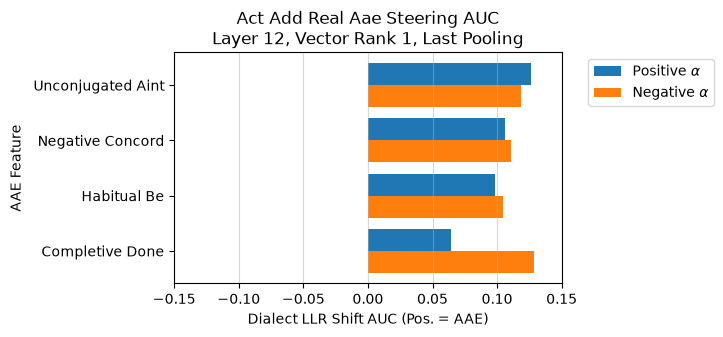

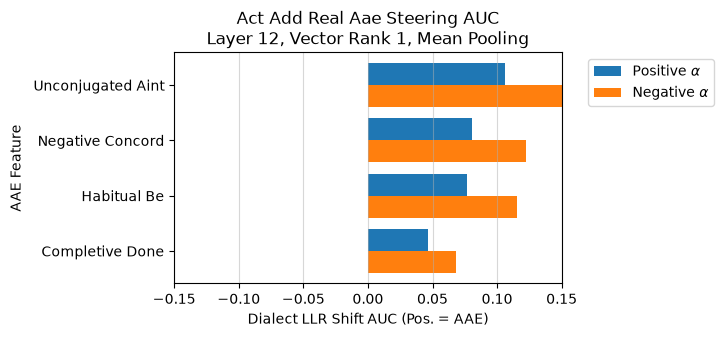

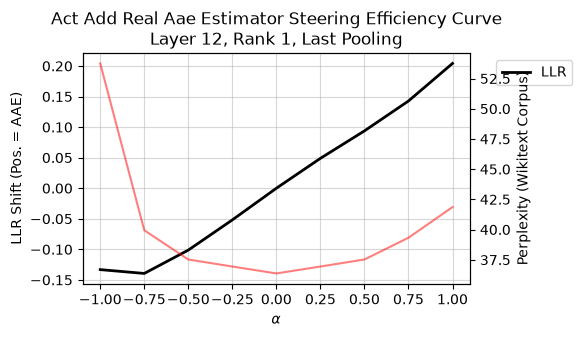

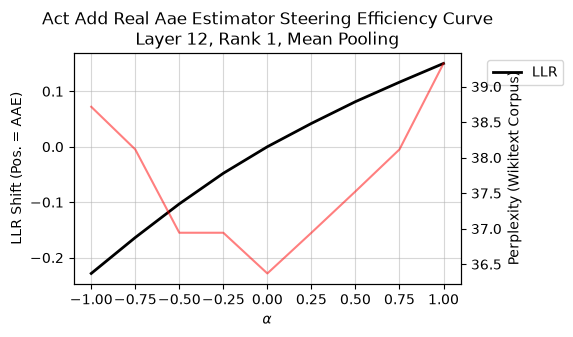

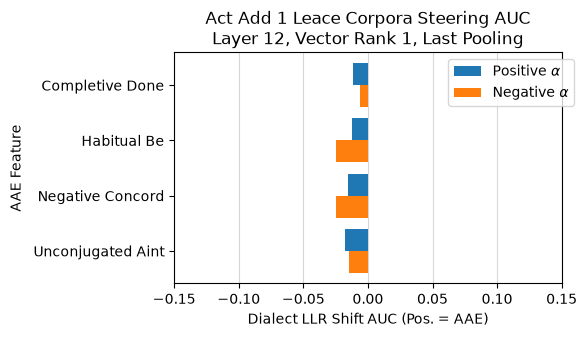

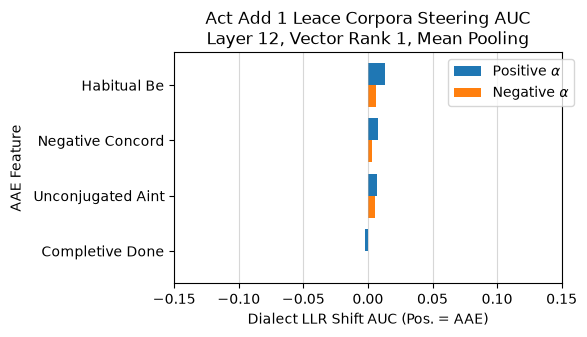

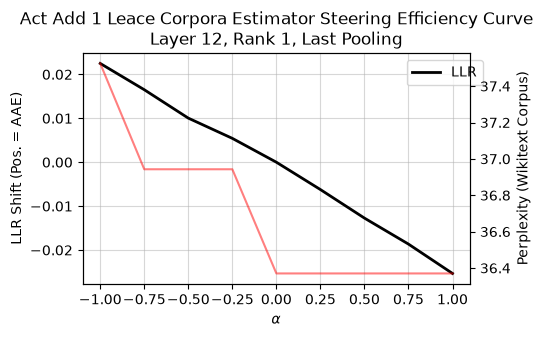

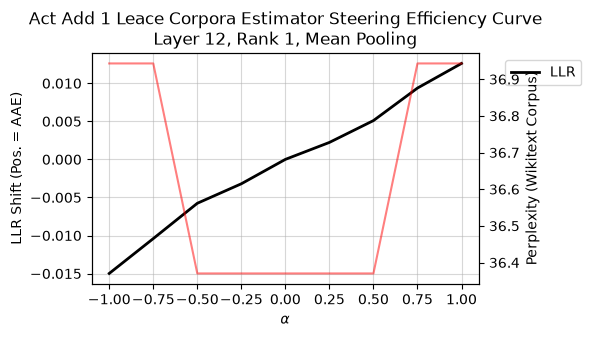

In [3]:
target_estimators = [
    f'{SingleEstimatorPrefixes.ACT_ADD}{supervised_corpus_name}',
    f'{SingleEstimatorPrefixes.ACT_ADD}{1}_leace_corpora',
]
for estimator_name in target_estimators:
    estimator_rank = target_rank if not estimator_name.startswith(SingleEstimatorPrefixes.ACT_ADD) else 1
    for pooling_type in PoolingTypeEnum:
        plot_estimator_feature_auc(
            auc_df,
            estimator_name,
            target_layer,
            estimator_rank,
            pooling_type,
            supervised_corpus_name,
            feature_names,
        )
    for pooling_type in PoolingTypeEnum:
        plot_llr_shift_and_perplexity_by_alpha(
            sweep_df,
            estimator_name,
            target_layer,
            estimator_rank,
            pooling_type,
            supervised_corpus_name,
            baseline_corpus_name,
        )

Missing Geometric Data
Missing Geometric Data
Missing Geometric Data


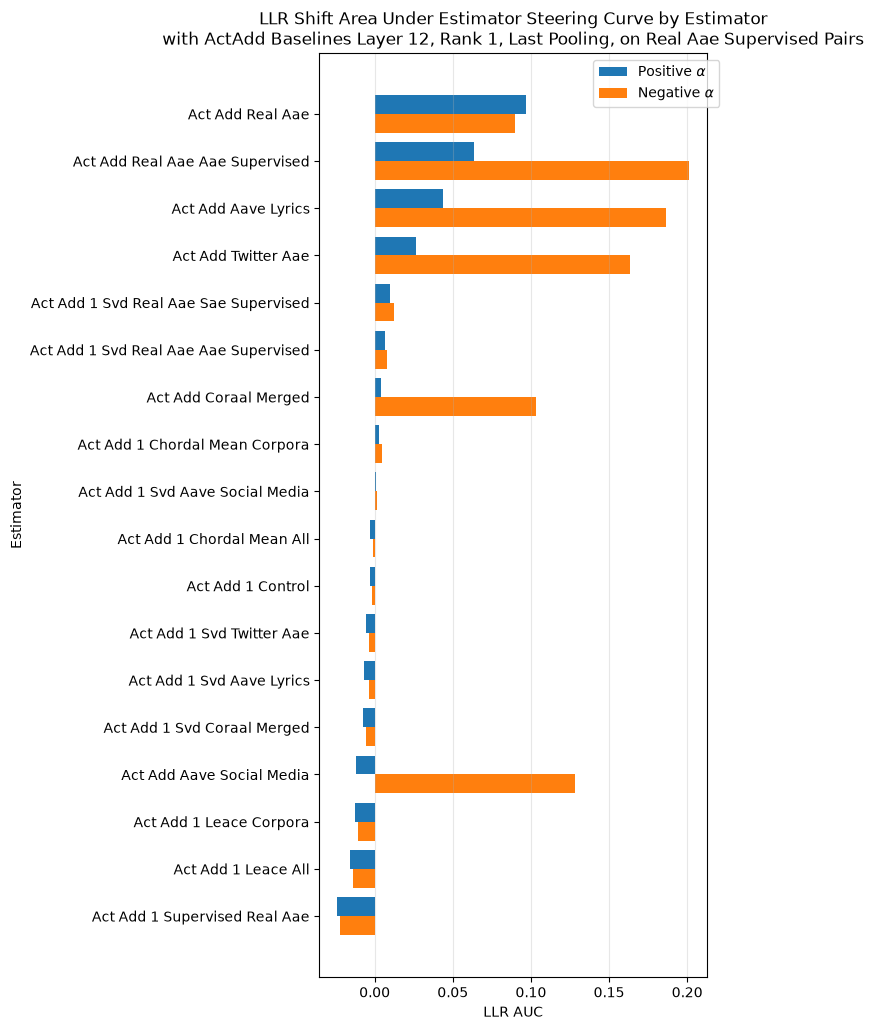

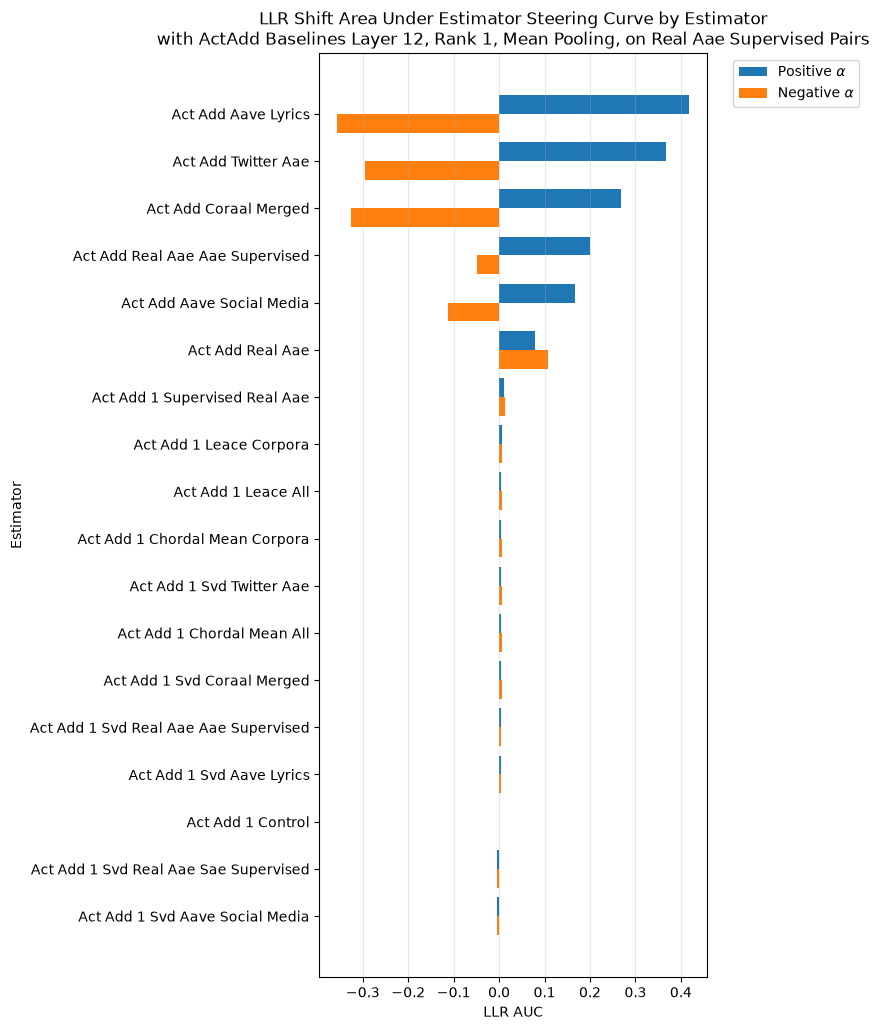

In [4]:
for pooling_type in PoolingTypeEnum:
    plot_supervised_chordal_distance_by_layer(
        geometric_results_df,
        EXPERIMENT_CONFIG.target_layers,
        target_rank,
        pooling_type,
        supervised_corpus_name,
        STYLE_MAP,
    )

plot_geometric_pooling_type_difference_by_layer(
    geometric_results_df,
    target_rank,
    EXPERIMENT_CONFIG.target_layers,
    supervised_corpus_name,
    STYLE_MAP,
)

for pooling_type in PoolingTypeEnum:
    plot_steering_auc_by_estimator(
        auc_df,
        target_layer,
        target_rank,
        pooling_type,
        supervised_corpus_name,
        include_act_add=True,
        figsize=(5, 12),
    )